# CaloDiffusion: threshold convention and near-zero-deposit audit

**Purpose:** use an existing final-report ZIP to audit native-cell occupancy, low-energy deposits,
spatial locations, and threshold sensitivity. No model loading, training, or GPU is required.
This notebook does not replace or edit your original study. All new results are labeled **post-hoc exploratory**.

## An unresolved source discrepancy
The pinned dataset-1 configs use `ECUT = 1e-7 GeV = 0.1 keV` for photon/pion.
The CaloDiffusion paper (v3, section IV.2) describes a **10 MeV** post-generation cutoff for dataset 1.
The electron config uses 15.1 keV; the challenge dataset documentation gives 15.15 keV.
These are different source statements, not evidence that one number should silently replace another.
The authors' currently public dataset-1 configs also contain 1e-7 GeV.

**A good fit must not determine the threshold.** Preserve the repository convention and report the
paper-described convention and a fixed sensitivity grid separately. Resolve the intended benchmark
convention with the checkpoint provider. Applying a common 10 MeV cut here does not reproduce every
sampling/evaluation setting of the paper and is not a claim of a new detector threshold.

Inputs: your saved `official_exports/`, geometry JSON, and manifest. Generated exports already have a
cutoff; lowering that cutoff cannot restore missing deposits. This notebook refuses scans below the
known generated cutoff and reports the mass at zero as a property of the saved exports.

## 1. Select an archive
Upload your final-report ZIP into a new Colab notebook session. Leave the default filename for the
all-particle run, or set `ARCHIVE_PATH`. No Google Drive mount or model repository is needed.
The local audit creates a new output directory. It reads specific archive entries rather than extracting
arbitrary paths and never unpickles the `.pt` snapshot files.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, io, json, zipfile, sys, platform
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

ARCHIVE_PATH = None  # Optional: '/content/your_final_report.zip'
DEFAULT_ARCHIVE = 'validated_calo_smoke_20261019T073144722177Z_final_report_20261019T080354263420Z'
PARTICLES_TO_AUDIT = ('photon', 'pion')
BOOTSTRAP_DRAWS = 500
AUDIT_SEED = 2026101901
# This is the known generated-export floor for the inspected source revision, not a detector claim.
EXPORT_FLOOR_GEV = {'electron': 1.51e-5, 'photon': 1e-7, 'pion': 1e-7}
DOCUMENTED_COMPARISON_GEV = {'electron': 15.15e-6, 'photon': 0.010, 'pion': 0.010}
PINNED_REVISION = '9694f81f602d1e2cd8c81c2d40aaf41d9b7806fa'

base = Path('/content') if Path('/content').is_dir() else Path.cwd()
if ARCHIVE_PATH is not None:
    archive_path = Path(ARCHIVE_PATH).expanduser().resolve()
else:
    choices = [base / DEFAULT_ARCHIVE, Path('/mnt/data') / DEFAULT_ARCHIVE]
    archive_path = next((p for p in choices if p.is_file()), None)
    if archive_path is None:
        try:
            from google.colab import files as colab_files
        except ImportError:
            raise FileNotFoundError('Set ARCHIVE_PATH to your existing final-report ZIP.')
        uploaded = colab_files.upload()
        names = [name for name in uploaded if name.lower().endswith('.zip')]
        if len(names) != 1:
            raise ValueError('Upload exactly one final-report ZIP, or set ARCHIVE_PATH explicitly.')
        archive_path = Path(names[0]).resolve()

if not archive_path.is_file():
    raise ValueError(f'File does not exist: {archive_path}')
elif archive_path.stat().st_size == 0:
    raise ValueError(f'The file exists but is empty (0 bytes): {archive_path}. Please re-upload your ZIP report.')
elif not zipfile.is_zipfile(archive_path):
    raise ValueError(f'Not a valid ZIP (it may be corrupted or partially uploaded): {archive_path}')

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(2**20), b''):
            h.update(chunk)
    return h.hexdigest()

INPUT_SHA256 = file_sha256(archive_path)
with zipfile.ZipFile(archive_path) as z:
    candidates = [n for n in z.namelist() if n.endswith('/manifest.json')]
    if len(candidates) != 1:
        raise ValueError('Expected one study manifest in this archive.')
    manifest_name = candidates[0]
    archive_root = manifest_name.rsplit('/', 1)[0]
    manifest = json.loads(z.read(manifest_name))
if manifest.get('revision') != PINNED_REVISION:
    raise ValueError('Source revision differs. Audit and update EXPORT_FLOOR_GEV before continuing.')
if not set(PARTICLES_TO_AUDIT).issubset(manifest['particles']):
    raise ValueError('A selected particle is not present in the saved run.')

stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
AUDIT_OUT = base / 'calodiffusion_threshold_audits' / f'{archive_root}_{stamp}'
for sub in ('tables', 'figures'):
    (AUDIT_OUT/sub).mkdir(parents=True, exist_ok=False)
print('Read-only input:', archive_path)
print('Input SHA256:', INPUT_SHA256)
print('New audit output:', AUDIT_OUT)
print('No model has been loaded or changed.')

Saving validated_calo_smoke_20261019T073144722177Z_final_report_20261019T080354263420Z.zip to validated_calo_smoke_20261019T073144722177Z_final_report_20261019T080354263420Z.zip
Read-only input: /content/validated_calo_smoke_20261019T073144722177Z_final_report_20261019T080354263420Z.zip
Input SHA256: ca036e72c7d32b14f3108c77a6801db8e8d7d922dacc1daf3637af15f2b8b530
New audit output: /content/calodiffusion_threshold_audits/validated_calo_smoke_20261019T073144722177Z_20261019T081708808383Z
No model has been loaded or changed.


## 2. Define the analysis before computing the new comparison
The fixed threshold grid spans the near-zero diagnostic region and the paper-described dataset-1 cut.
`deposits < threshold` are zeroed for energy sums; hit counts use `deposit > threshold`, matching the
original notebook. Counts exactly at the boundary are reported so an equality convention is visible.

Intervals below resample **whole showers independently within each sample**, not individual cells.
They are exploratory percentile-bootstrap intervals for a difference in mean occupancy, conditional on
this selected energy sample and single saved generation run. They do not establish training independence.

In [3]:
CUTS_GEV = {}
for particle in PARTICLES_TO_AUDIT:
    if particle == 'electron':
        values = [1.51e-5, 1.515e-5, 3e-5, 1e-4, 1e-3, 1e-2]
    else:
        values = [1e-7, 3e-7, 1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 1e-3, 1e-2]
    CUTS_GEV[particle] = np.asarray(values, dtype=float)
    if np.any(CUTS_GEV[particle] < EXPORT_FLOOR_GEV[particle]):
        raise ValueError('Cannot undo the cutoff already applied to the generated exports.')

threshold_plan = {
    'status': 'posthoc_exploratory',
    'source_archive_sha256': INPUT_SHA256,
    'source_run': manifest['run_tag'],
    'source_revision': manifest['revision'],
    'thresholds_GeV': {p: x.tolist() for p,x in CUTS_GEV.items()},
    'known_export_floor_GeV': EXPORT_FLOOR_GEV,
    'documented_comparison_GeV': DOCUMENTED_COMPARISON_GEV,
    'energy_rule': 'zero deposits strictly below threshold',
    'hit_rule': 'deposit strictly greater than threshold',
    'reference_independence': manifest['reference_is_unseen_by_checkpoint'],
    'bootstrap_resampling_unit': 'whole shower; independent samples; selected windows fixed',
    'bootstrap_draws': BOOTSTRAP_DRAWS,
    'seed': AUDIT_SEED,
}
(AUDIT_OUT/'audit_plan.json').write_text(json.dumps(threshold_plan, indent=2))
display(pd.DataFrame([{'particle':p,'threshold_GeV':t,'threshold_keV':t*1e6,
                     'threshold_MeV':t*1e3} for p,ts in CUTS_GEV.items() for t in ts]))

,particle,threshold_GeV,threshold_keV,threshold_MeV
0,photon,1.000000e-07,0.1,0.0001
1,photon,3.000000e-07,0.3,0.0003
2,photon,1.000000e-06,1.0,0.0010
3,photon,3.000000e-06,3.0,0.0030
4,photon,1.000000e-05,10.0,0.0100
5,photon,3.000000e-05,30.0,0.0300
6,photon,1.000000e-04,100.0,0.1000
7,photon,1.000000e-03,1000.0,1.0000
8,photon,1.000000e-02,10000.0,10.0000
9,pion,1.000000e-07,0.1,0.0001


## 3. Read native geometry and reference/generated exports
Energy arrays in the exported HDF5 files are in MeV and are converted exactly once to GeV.
Coordinates come from the saved native geometry metadata. Radial centers label a cell, not a sub-cell
measurement; depth is active-layer ordinal, not physical distance. The arrays are never rebinned to count hits.

Equal incident-energy rows do not make a generated shower a reconstruction of the corresponding
reference shower. We compare ensemble statistics; no generated-versus-reference eventwise IoU is computed.

In [4]:
def read_member(name, max_bytes=2*1024**3):
    with zipfile.ZipFile(archive_path) as z:
        info = z.getinfo(f'{archive_root}/{name}')
        if info.file_size > max_bytes:
            raise ValueError('Archive member too large for this in-memory audit; use chunked local HDF5 reads.')
        return z.read(info)

def native_metadata(g):
    rows = []; index = 0
    for ordinal, (layer, na, edges) in enumerate(zip(g['layer_ids'], g['n_angles'], g['radial_edges'])):
        edges = np.asarray(edges, dtype=float)
        if na < 1 or len(edges)<2 or not np.all(np.diff(edges)>0):
            raise ValueError('Invalid saved native geometry.')
        for angular in range(na):
            for radial in range(len(edges)-1):
                rows.append(dict(cell=index, layer_id=int(layer), layer_ordinal=ordinal,
                                 angular_bin=angular, radial_bin=radial, n_angles=na,
                                 radius_low=edges[radial], radius_high=edges[radial+1],
                                 radius_center=0.5*(edges[radial]+edges[radial+1])))
                index += 1
    return pd.DataFrame(rows)

def read_export(particle, sample):
    with h5py.File(io.BytesIO(read_member(f'official_exports/{particle}_{sample}.hdf5')), 'r') as f:
        unit = f.attrs.get('energy_unit', '')
        if isinstance(unit, bytes): unit = unit.decode()
        if unit != 'MeV':
            raise ValueError(f'Unverified input energy unit: {unit!r}')
        e = np.asarray(f['incident_energies'][:],dtype=np.float64).reshape(-1)/1000.
        x = np.asarray(f['showers'][:],dtype=np.float64).reshape(len(e),-1)/1000.
    if not np.isfinite(x).all() or (x<0).any() or not np.isfinite(e).all() or (e<=0).any():
        raise ValueError('Invalid physical deposits or incident energies.')
    return e,x

SAMPLES, METADATA, STRATA = {}, {}, {}
for particle in PARTICLES_TO_AUDIT:
    g=json.loads(read_member(f'{particle}_geometry.json'))
    METADATA[particle]=native_metadata(g)
    METADATA[particle].to_csv(AUDIT_OUT/'tables'/f'{particle}_native_cell_metadata.csv',index=False)
    pairs={name:read_export(particle,name) for name in ('reference','generated')}
    er,xr=pairs['reference'];eg,xg=pairs['generated']
    if not np.array_equal(er,eg) or xr.shape!=xg.shape or xr.shape[1]!=len(METADATA[particle]):
        raise ValueError('Input condition matching or native geometry check failed.')
    SAMPLES[particle]=pairs
    if particle=='electron':
        STRATA[particle]=[(f'{lo:g}-{hi:g}GeV', (er>=lo)&(er<hi))
                         for lo,hi in manifest['config']['electron_windows']]
    else:
        STRATA[particle]=[(f'{e:g}GeV',np.isclose(er,e,rtol=2e-5,atol=1e-7))
                         for e in manifest['config']['discrete_energies']]
    print(particle, xr.shape, '| native geometry and energy matching passed')

photon (96, 368) | native geometry and energy matching passed
pion (96, 533) | native geometry and energy matching passed


## 4. Compute threshold curves without losing the zero population
For every sample and energy stratum, report occupancy, hit count, response and response width,
zero-cell fraction, exact-boundary count, and energy removed by each cut. Histograms later report
**mean number of cells per shower per energy bin**, not a density normalized only over positive cells.
This preserves the distinction between many extra tiny hits and appreciable extra deposited energy.

In [5]:
EVENTS=[]; CELLS=[]; SPECTRA=[]
for particle in PARTICLES_TO_AUDIT:
    meta=METADATA[particle]
    for label,selection in STRATA[particle]:
        if not selection.any(): raise ValueError(f'Empty energy selection: {particle}/{label}')
        for sample,(energy,xall) in SAMPLES[particle].items():
            x=xall[selection]; e=energy[selection]; totals=x.sum(axis=1)
            n,v=x.shape
            # Separate zero mass; hist bins omit exact zeros by design and report their count separately.
            max_positive=max(float(x.max()), float(CUTS_GEV[particle][-1])*1.01)
            # Same edges for both samples: use both groups, explicitly descriptive rather than fit selection.
            pairmax=max(float(SAMPLES[particle][s][1][selection].max()) for s in ('reference','generated'))
            bins=np.geomspace(EXPORT_FLOOR_GEV[particle],max(pairmax,0.011)*1.0001,61)
            hist=np.histogram(x[x>0],bins=bins)[0]/n
            for j,h in enumerate(hist):
                SPECTRA.append(dict(particle=particle,stratum=label,sample=sample,
                    low_GeV=bins[j],high_GeV=bins[j+1],mean_cells_per_shower=h,
                    mean_zero_cells=float((x==0).sum(axis=1).mean()),
                    mean_positive_below_first_bin=float(((x>0)&(x<bins[0])).sum(axis=1).mean())))
            for tau in CUTS_GEV[particle]:
                active=x>tau; kept=np.where(x<tau,0.,x); total=kept.sum(axis=1)
                fraction_removed=np.divide(totals-total,totals,out=np.full(n,np.nan),where=totals>0)
                hitcounts=active.sum(axis=1)
                frame=pd.DataFrame(dict(export_row=np.flatnonzero(selection),energy_GeV=e,
                    nhits=hitcounts,occupancy=hitcounts/v, deposited_GeV=total,response=total/e,
                    removed_energy_fraction=fraction_removed,zero_fraction=(x==0).mean(axis=1),
                    exact_boundary_cells=(x==tau).sum(axis=1),empty_shower=(total==0)))
                frame['particle']=particle;frame['stratum']=label;frame['sample']=sample;frame['cut_GeV']=tau
                layer_totals=np.stack([kept[:,meta.layer_ordinal.to_numpy()==j].sum(axis=1)
                                      for j in sorted(meta.layer_ordinal.unique())],axis=1)
                for j in range(layer_totals.shape[1]):
                    frame[f'layer_fraction_{j}']=np.divide(layer_totals[:,j],total,
                        out=np.full(n,np.nan),where=total>0)
                frame['depth_layer']=np.divide(kept@meta.layer_ordinal.to_numpy(),total,
                                                out=np.full(n,np.nan),where=total>0)
                EVENTS.append(frame)
                cellframe=meta.copy()
                cellframe['hit_probability']=active.mean(axis=0)
                # 'Tiny' is above the export floor but below this trial threshold.
                tiny=(x>EXPORT_FLOOR_GEV[particle]) & (x<tau)
                cellframe['tiny_probability']=tiny.mean(axis=0)
                cellframe['mean_tiny_energy_GeV']=np.where(tiny,x,0.).mean(axis=0)
                cellframe['mean_kept_energy_GeV']=kept.mean(axis=0)
                cellframe['particle']=particle;cellframe['stratum']=label
                cellframe['sample']=sample;cellframe['cut_GeV']=tau
                CELLS.append(cellframe)
EVENTS=pd.concat(EVENTS,ignore_index=True)
CELLS=pd.concat(CELLS,ignore_index=True)
SPECTRA=pd.DataFrame(SPECTRA)
EVENTS.to_csv(AUDIT_OUT/'tables'/'threshold_event_metrics.csv.gz',index=False,compression='gzip')
CELLS.to_csv(AUDIT_OUT/'tables'/'native_cell_probability_maps.csv.gz',index=False,compression='gzip')
SPECTRA.to_csv(AUDIT_OUT/'tables'/'cell_energy_histograms.csv',index=False)
SUMMARY=EVENTS.groupby(['particle','stratum','sample','cut_GeV'],as_index=False).agg(
    n_events=('export_row','size'),occupancy_mean=('occupancy','mean'),nhits_mean=('nhits','mean'),
    response_mean=('response','mean'),response_std=('response','std'),
    removed_energy_fraction_mean=('removed_energy_fraction','mean'),
    zero_fraction_mean=('zero_fraction','mean'),exact_boundary_cells=('exact_boundary_cells','sum'))
SUMMARY.to_csv(AUDIT_OUT/'tables'/'threshold_summary.csv',index=False)

rng=np.random.default_rng(AUDIT_SEED); effects=[]
for keys,g in EVENTS.groupby(['particle','stratum','cut_GeV']):
    r=g.loc[g['sample']=='reference','occupancy'].to_numpy()
    s=g.loc[g['sample']=='generated','occupancy'].to_numpy()
    boot=np.array([rng.choice(s,len(s),replace=True).mean()-rng.choice(r,len(r),replace=True).mean()
                   for _ in range(BOOTSTRAP_DRAWS)])
    lo,hi=np.quantile(boot,[.025,.975])
    effects.append(dict(particle=keys[0],stratum=keys[1],cut_GeV=keys[2],
                        occupancy_difference=s.mean()-r.mean(),lo=lo,hi=hi))
EFFECTS=pd.DataFrame(effects)
EFFECTS.to_csv(AUDIT_OUT/'tables'/'occupancy_differences.csv',index=False)
display(SUMMARY)

,particle,stratum,sample,cut_GeV,n_events,occupancy_mean,nhits_mean,response_mean,response_std,removed_energy_fraction_mean,zero_fraction_mean,exact_boundary_cells
0,photon,32.768GeV,generated,1.000000e-07,32,0.936226,344.53125,0.973160,0.022753,0.000000e+00,0.063774,0
1,photon,32.768GeV,generated,3.000000e-07,32,0.921535,339.12500,0.973160,0.022753,3.309717e-08,0.063774,0
2,photon,32.768GeV,generated,1.000000e-06,32,0.884596,325.53125,0.973159,0.022753,2.916966e-07,0.063774,0
3,photon,32.768GeV,generated,3.000000e-06,32,0.863536,317.78125,0.973159,0.022753,6.451986e-07,0.063774,0
4,photon,32.768GeV,generated,1.000000e-05,32,0.855893,314.96875,0.973159,0.022753,1.101797e-06,0.063774,0
...,...,...,...,...,...,...,...,...,...,...,...,...
103,pion,8.192GeV,reference,1.000000e-05,32,0.305523,162.84375,0.713514,0.169665,1.971395e-06,0.688673,0
104,pion,8.192GeV,reference,3.000000e-05,32,0.301360,160.62500,0.713509,0.169664,8.978409e-06,0.688673,0
105,pion,8.192GeV,reference,1.000000e-04,32,0.287817,153.40625,0.713449,0.169664,9.801954e-05,0.688673,0
106,pion,8.192GeV,reference,1.000000e-03,32,0.224789,119.81250,0.711625,0.169923,2.943728e-03,0.688673,0


## 5. Inspect the threshold sensitivity and cell-energy spectrum
The figures use the middle energy selection for readability; saved tables contain every selection.
The vertical marker is the separately documented comparison, not a best-fit threshold.
Changing a cutoff changes the observable. A discrepancy disappearing at a higher cutoff localizes
its energy scale but does not automatically validate the generator or select a detector threshold.

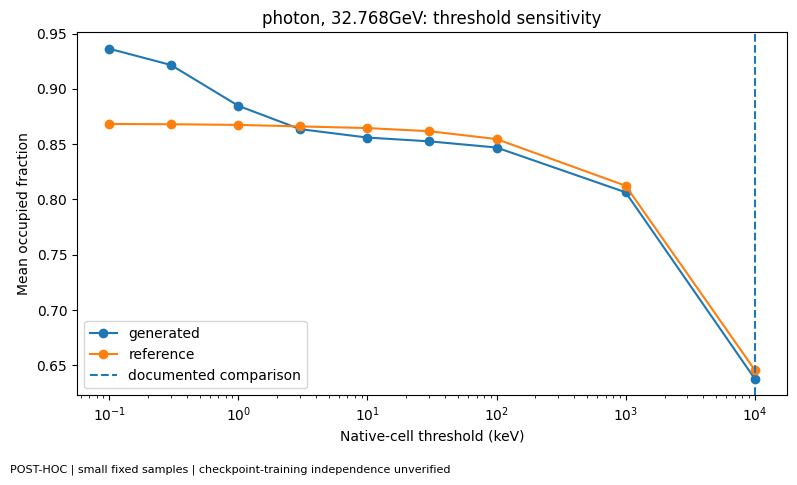

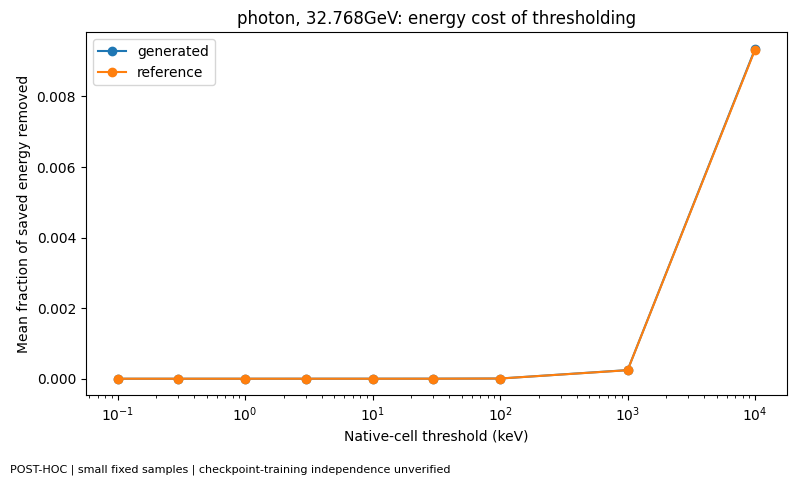

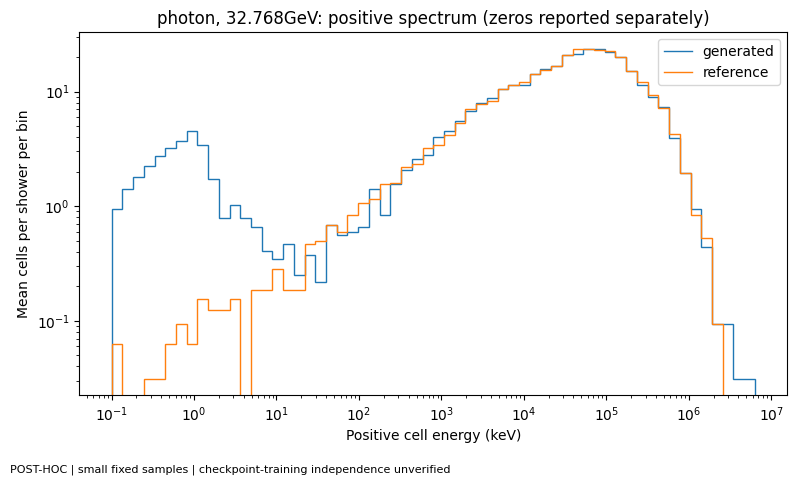

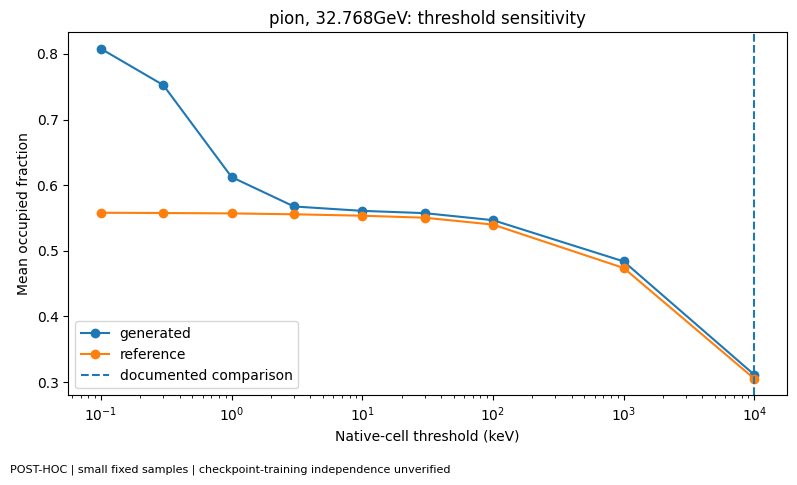

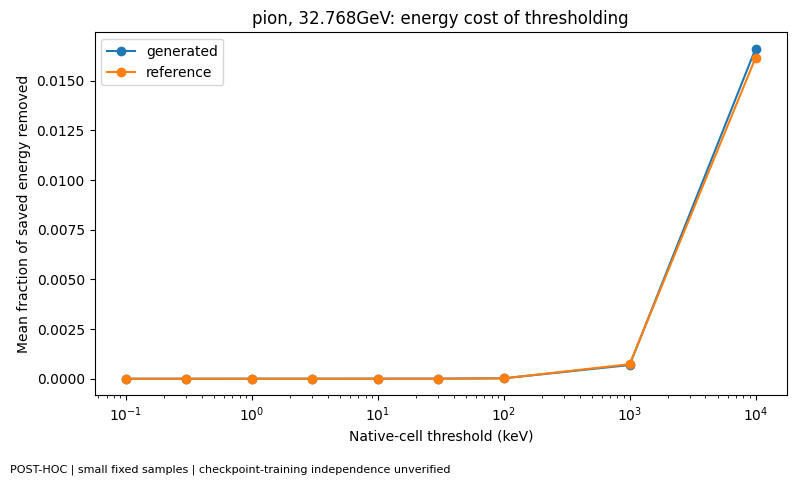

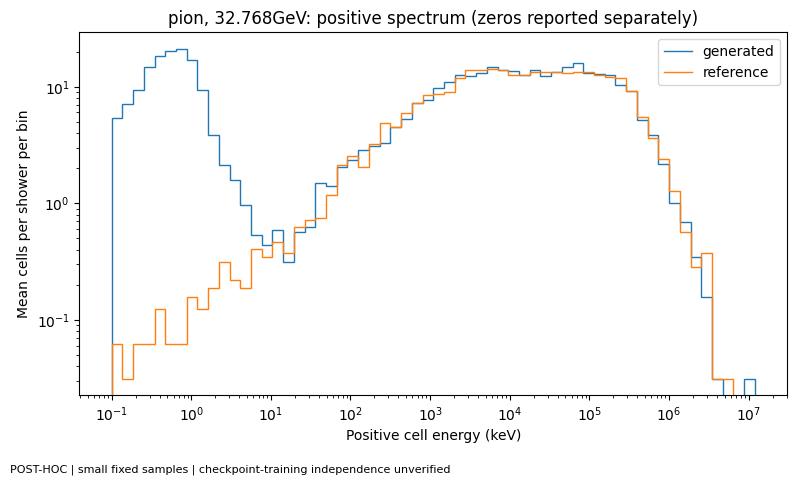

In [6]:
def save_figure(name):
    plt.gcf().text(.01,.005,'POST-HOC | small fixed samples | checkpoint-training independence unverified',fontsize=8)
    plt.tight_layout(rect=(0,.035,1,1))
    plt.savefig(AUDIT_OUT/'figures'/f'{name}.png',dpi=140,bbox_inches='tight')
    plt.show();plt.close()

for particle in PARTICLES_TO_AUDIT:
    label=STRATA[particle][1][0]
    s=SUMMARY[(SUMMARY.particle==particle)&(SUMMARY.stratum==label)]
    fig,ax=plt.subplots(figsize=(8,4.8))
    for sample,g in s.groupby('sample'):
        g=g.sort_values('cut_GeV');ax.plot(g.cut_GeV*1e6,g.occupancy_mean,marker='o',label=sample)
    ax.axvline(DOCUMENTED_COMPARISON_GEV[particle]*1e6,linestyle='--',label='documented comparison')
    ax.set(xscale='log',xlabel='Native-cell threshold (keV)',ylabel='Mean occupied fraction',
           title=f'{particle}, {label}: threshold sensitivity')
    ax.legend();save_figure(f'{particle}_occupancy_threshold')

    fig,ax=plt.subplots(figsize=(8,4.8))
    for sample,g in s.groupby('sample'):
        g=g.sort_values('cut_GeV');ax.plot(g.cut_GeV*1e6,g.removed_energy_fraction_mean,marker='o',label=sample)
    ax.set(xscale='log',xlabel='Native-cell threshold (keV)',ylabel='Mean fraction of saved energy removed',
           title=f'{particle}, {label}: energy cost of thresholding')
    ax.legend();save_figure(f'{particle}_removed_energy')

    fig,ax=plt.subplots(figsize=(8,4.8))
    for sample,g in SPECTRA[(SPECTRA.particle==particle)&(SPECTRA.stratum==label)].groupby('sample'):
        g=g.sort_values('low_GeV')
        ax.stairs(g.mean_cells_per_shower,np.r_[g.low_GeV.to_numpy(),g.high_GeV.iloc[-1]]*1e6,label=sample)
    ax.set(xscale='log',yscale='log',xlabel='Positive cell energy (keV)',ylabel='Mean cells per shower per bin',
           title=f'{particle}, {label}: positive spectrum (zeros reported separately)')
    ax.legend();save_figure(f'{particle}_positive_cell_spectrum')

## 6. Locate the extra small deposits without inventing event-level truth pairing
Compare per-native-cell probabilities across ensembles. Save both hit-probability and tiny-deposit
probability differences. Aggregate by original layer/radial ring to distinguish whether the excess is
in shower cores, outer radial rings, or particular layers. The denominator is native cells in that group;
raw cell counts across differently segmented regions should not be treated as probabilities.

A generation cannot be declared to have a 'false positive at cell i' by pairing it with an unrelated
reference shower. Here a positive difference means a higher **ensemble probability** at that coordinate.

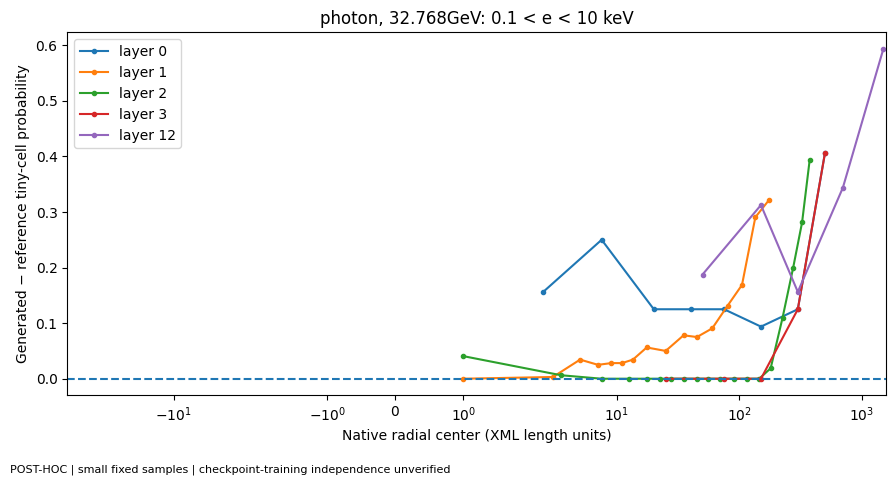

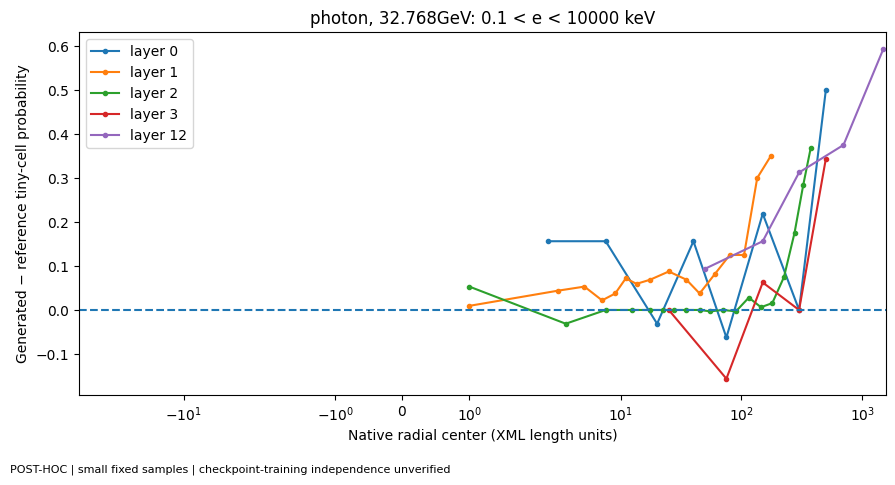

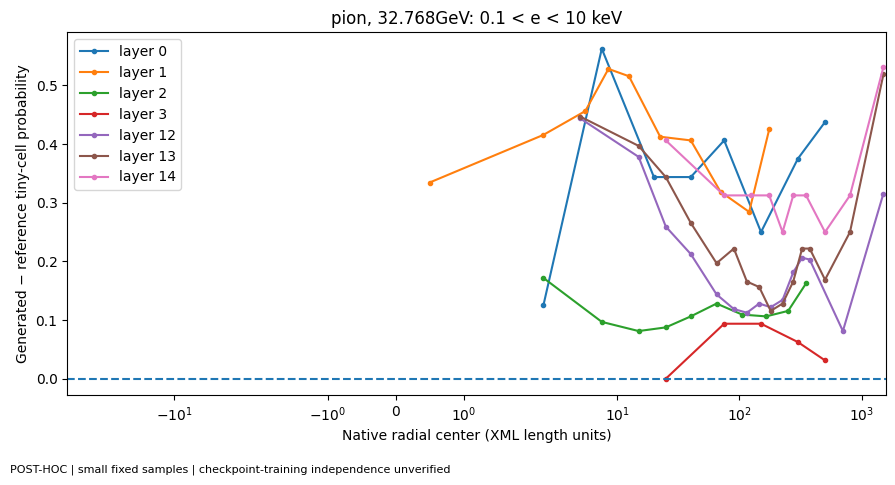

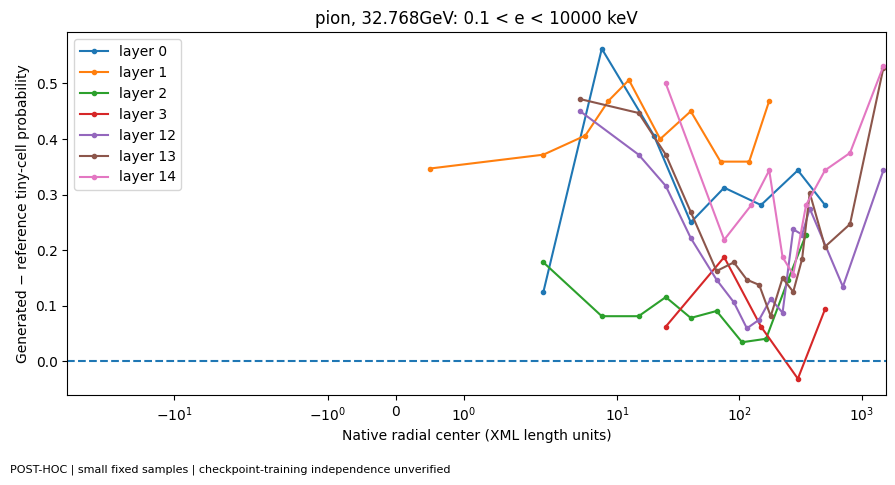

In [7]:
keys=['particle','stratum','cut_GeV','cell','layer_id','layer_ordinal','angular_bin',
      'radial_bin','n_angles','radius_low','radius_high','radius_center']
cols=['hit_probability','tiny_probability','mean_tiny_energy_GeV','mean_kept_energy_GeV']
r=CELLS[CELLS['sample']=='reference'][keys+cols]
s=CELLS[CELLS['sample']=='generated'][keys+cols]
MAPS=s.merge(r,on=keys,suffixes=('_generated','_reference'),validate='one_to_one')
for col in cols:
    MAPS[col+'_difference']=MAPS[col+'_generated']-MAPS[col+'_reference']
MAPS.to_csv(AUDIT_OUT/'tables'/'native_cell_differences.csv.gz',index=False,compression='gzip')
LAYER=CELLS.groupby(['particle','stratum','sample','cut_GeV','layer_id'],as_index=False).agg(
    mean_hit_probability=('hit_probability','mean'),mean_tiny_probability=('tiny_probability','mean'),
    mean_tiny_energy_in_layer_GeV=('mean_tiny_energy_GeV','sum'),
    mean_kept_energy_in_layer_GeV=('mean_kept_energy_GeV','sum'))
LAYER.to_csv(AUDIT_OUT/'tables'/'layer_threshold_summary.csv',index=False)

for particle in PARTICLES_TO_AUDIT:
    label=STRATA[particle][1][0]
    # Predefined near-zero comparison and separately documented convention; neither was fitted.
    for tau in sorted(set([max(1e-5,EXPORT_FLOOR_GEV[particle]),DOCUMENTED_COMPARISON_GEV[particle]])):
        g=MAPS[(MAPS.particle==particle)&(MAPS.stratum==label)&np.isclose(MAPS.cut_GeV,tau,rtol=1e-10,atol=0)]
        if g.empty: continue
        fig,ax=plt.subplots(figsize=(9,4.8))
        for layer,layerrows in g.groupby('layer_id'):
            ring=layerrows.groupby('radius_center')['tiny_probability_difference'].mean()
            ax.plot(ring.index,ring.values,marker='.',label=f'layer {layer}')
        ax.axhline(0,linestyle='--')
        ax.set(xscale='symlog',xlabel='Native radial center (XML length units)',
               ylabel='Generated − reference tiny-cell probability',
               title=f'{particle}, {label}: {EXPORT_FLOOR_GEV[particle]*1e6:g} < e < {tau*1e6:g} keV')
        ax.legend();save_figure(f'{particle}_tiny_map_{tau:g}GeV')

## 7. Provenance record: what is known and what is not
A local calibration/pilot/test split is not proof that the checkpoint did not see those events.
The pinned configuration names `dataset_1_*_1.hdf5` under FILES and `dataset_1_*_2.hdf5` under EVAL.
That makes the latter a candidate reference source, not evidence about the training history of a specific
checkpoint. The source README identifies Zenodo releases but does not give the cache extraction row map.

Ask the checkpoint provider for: checkpoint hash; exact training and validation filenames/releases and
checksums; row ranges/event IDs (including validation used for checkpoint selection); any fine-tuning;
the script/seed/source-row mapping used to build the 12k-event cache; and the evaluation threshold command.

Different whole-file checksums do not prove disjointness: a subset and its parent necessarily hash
differently. Exact canonical event hashes can find duplicated content; a non-match is only meaningful
when units, geometry, precision, and transformations are identical and the searched training corpus is complete.

In [8]:
expected_files={
 'electron': ('dataset_2_1.hdf5','dataset_2_2.hdf5'),
 'photon': ('dataset_1_photons_1.hdf5','dataset_1_photons_2.hdf5'),
 'pion': ('dataset_1_pions_1.hdf5','dataset_1_pions_2.hdf5'),
}
provenance=[]
for p in PARTICLES_TO_AUDIT:
    provenance.append(dict(
        particle=p,checkpoint_sha256=manifest['checkpoints'][p]['sha256'],
        cache_sha256=manifest['reference_files'][p]['sha256'],
        candidate_training_file=expected_files[p][0],candidate_eval_file=expected_files[p][1],
        actual_checkpoint_training_files_verified=False,
        original_cache_parent_file='UNKNOWN',original_cache_row_mapping='UNKNOWN',
        checkpoint_selection_exposure='UNKNOWN',evaluation_threshold_command='UNKNOWN',
        reference_status='UNVERIFIED: exploratory comparison only'))
(AUDIT_OUT/'provenance_questions.json').write_text(json.dumps(provenance,indent=2))
display(pd.DataFrame(provenance))

# Supporting duplicate-screening utility: use identically represented RAW reference/training records.
# Quantizing to float32 is a declared comparison convention, not universal event identity.
def canonical_event_sha256(showers_mev, incident_mev):
    x=np.asarray(showers_mev,dtype='<f4');e=np.asarray(incident_mev,dtype='<f4').reshape(-1)
    if x.ndim!=2 or len(x)!=len(e) or not np.isfinite(x).all() or not np.isfinite(e).all():
        raise ValueError('Expected finite native raw MeV arrays with matching event count.')
    shape_tag=np.asarray([x.shape[1]],dtype='<u8').tobytes()
    return np.array([hashlib.sha256(shape_tag+e[j:j+1].tobytes()+np.ascontiguousarray(x[j]).tobytes()).hexdigest()
                     for j in range(len(e))])

,particle,checkpoint_sha256,cache_sha256,candidate_training_file,candidate_eval_file,actual_checkpoint_training_files_verified,original_cache_parent_file,original_cache_row_mapping,checkpoint_selection_exposure,evaluation_threshold_command,reference_status
0,photon,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,c8cd08f333d7d73c453cec39de6c5054de3a8940b63f30...,dataset_1_photons_1.hdf5,dataset_1_photons_2.hdf5,False,UNKNOWN,UNKNOWN,UNKNOWN,UNKNOWN,UNVERIFIED: exploratory comparison only
1,pion,77fa86ea1ce6fefe90685019ad45ce13408a2ee33d3683...,3b947455ce76178708b85364f108273ece694e7dbade28...,dataset_1_pions_1.hdf5,dataset_1_pions_2.hdf5,False,UNKNOWN,UNKNOWN,UNKNOWN,UNKNOWN,UNVERIFIED: exploratory comparison only


## 8. Follow-up experiments: planning, not an automatic retraining command

### Lock the reference split independently of generator randomness
Use a dedicated reference-partition seed, an event-ID blacklist for **all smoke-study events already
inspected** (calibration, pilot, and test), and a fixed list of new generation seeds. Keep the same
held-out reference pool across generation repeats, and do not count it repeatedly as new reference data.
A reference event in one split must not reappear in another split under a new seed or a renamed file.

For each particle/energy selection, first count available unexposed reference events. This existing
pipeline needs `n_calibration >= n_test` for its unique scale-only donors and
`n_pilot >= trace_events_per_run * trace_runs`. A **proposed intermediate study**, not a power guarantee:
256 calibration + 128 pilot + 256 test events per stratum, three generator repeats, 64 emergence
trajectories, and 32 branching parents with eight continuations per parent. Stop if the data cannot
support that split; never duplicate events or silently relax the partition rules.

For a precision target h on a mean difference, a planning approximation for equal sample sizes is
`n ≈ 1.96**2 * (s_reference**2 + s_generator**2) / h**2`. Choose the practically meaningful h before
viewing a fresh test sample. Response widths and tail probabilities need their own uncertainty study;
there is no universal sufficient sample count.

### Store spatial support during the next traces
The original emergence CSV contains scalar summaries, not all intermediate native-cell masks.
You cannot recover support overlap from occupancy counts alone. Record masks at selected fixed
thresholds while the tracer receives xhat_0, with `np.packbits(mask, axis=-1)`, plus the final mask,
actual timestep, event ID and number of native voxels. This is a diagnostic addition; rerun the
unchanged sampler/hook-neutrality gate after editing the tracer.

Use the support helpers in the next cell for **the same generated event at two steps** or two
continuations of the same parent. Do not compare a generated shower row with an unrelated Geant4 row.
High hit-IoU can be trivial when both masks are saturated, so report empty-cell IoU, false additions,
missed final cells, and an all-active baseline as well. Both-empty support cases are marked undefined
and counted rather than silently scored as perfect. Per-cell normalized-energy total variation adds
energy-weighted spatial information beyond binary support.

In [9]:
def support_metrics(current, final, threshold_gev):
    a=np.asarray(current,dtype=np.float64);b=np.asarray(final,dtype=np.float64)
    if a.shape!=b.shape or a.ndim!=2 or threshold_gev<0:
        raise ValueError('Expected corresponding (events, native voxels) arrays and nonnegative cut.')
    if not np.isfinite(a).all() or not np.isfinite(b).all() or (a<0).any() or (b<0).any():
        raise ValueError('Provide finite nonnegative PHYSICAL native arrays.')
    A=a>threshold_gev;B=b>threshold_gev
    def div(x,y):
        return np.divide(x,y,out=np.full(np.shape(x),np.nan,dtype=float),where=y!=0)
    intersection=(A&B).sum(1);union=(A|B).sum(1)
    empty_intersection=((~A)&(~B)).sum(1);empty_union=((~A)|(~B)).sum(1)
    ka=np.where(A,a,0.);kb=np.where(B,b,0.)
    ea=ka.sum(1);eb=kb.sum(1)
    sa=div(ka,ea[:,None]);sb=div(kb,eb[:,None])
    # Caller must use a predeclared criterion and report undefined/insufficient-tail cases.
    return pd.DataFrame(dict(hit_iou=div(intersection,union),empty_iou=div(empty_intersection,empty_union),
        precision_to_own_final=div(intersection,A.sum(1)),recall_of_own_final=div(intersection,B.sum(1)),
        false_added_fraction_of_voxels=(A&~B).mean(1),missed_fraction_of_voxels=(~A&B).mean(1),
        hamming_fraction=(A!=B).mean(1),all_active_hit_iou_baseline=B.mean(1),
        both_hit_sets_empty=(union==0),both_empty_sets_empty=(empty_union==0),
        normalized_energy_total_variation=0.5*np.abs(sa-sb).sum(1)))

# Illustrative unit check, NOT a CaloDiffusion result:
a=np.array([[1.,0.,2.,0.]])
b=np.array([[0.,1.,0.,2.]])
assert (a>0).sum()==(b>0).sum()
assert support_metrics(a,b,0.)['hit_iou'].iloc[0]==0.
assert support_metrics(a,a,0.)['hit_iou'].iloc[0]==1.
assert np.isnan(support_metrics(np.zeros_like(a),np.zeros_like(a),0.)['hit_iou'].iloc[0])
print('Support helper tests passed: equal hit counts do not imply equal occupied cells.')

Support helper tests passed: equal hit counts do not imply equal occupied cells.


## 9. Save the audit independently of the original run
The output archive contains a convention plan, summary/event/cell maps, figures and a provenance
questionnaire. It does not contain new model results or a completed large-sample study.
The original input ZIP checksum is rechecked to establish that this audit did not change it.

In [10]:
if file_sha256(archive_path)!=INPUT_SHA256:
    raise RuntimeError('The input archive changed during the audit.')
report='\n'.join([
 '# Threshold audit: post-hoc exploratory',
 f'Original run: {manifest["run_tag"]}',
 f'Original ZIP SHA256: {INPUT_SHA256}',
 f'Source revision: {manifest["revision"]}',
 'No model generation or retraining was performed. Original archive unchanged.',
 'The public paper and supplied dataset-1 ECUT configurations disagree.',
 'Keep threshold variants separate. No threshold is selected based on the best fit.',
 'Reference independence from checkpoint training remains unverified.',
 'Generated exports cannot recover deposits already set to zero below their original cutoff.',
 'Cell-level probabilities are ensemble comparisons, not eventwise truth reconstruction.',
 'Suggested next step: resolve convention/provenance and freeze a fresh event split before scaling up.'
])
(AUDIT_OUT/'audit_report.md').write_text(report)
(AUDIT_OUT/'audit_environment.json').write_text(json.dumps({
    'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,
    'h5py':h5py.__version__,'reference_provenance':manifest.get('reference_provenance')},indent=2))
archive_out=AUDIT_OUT.with_suffix('.zip')
with zipfile.ZipFile(archive_out,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in AUDIT_OUT.rglob('*'):
        if p.is_file(): z.write(p,arcname=str(Path(AUDIT_OUT.name)/p.relative_to(AUDIT_OUT)))
print('AUDIT SAVED:',archive_out)
print('SHA256:',file_sha256(archive_out))
# In Colab, run this separately to download:
from google.colab import files as colab_files
colab_files.download(str(archive_out))

AUDIT SAVED: /content/calodiffusion_threshold_audits/validated_calo_smoke_20261019T073144722177Z_20261019T081708808383Z.zip
SHA256: eeae9cc228dd9ab37d2c0c4a844618ef8113de196017859c672764a00ecb9013


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sources and boundaries
Source verification date: 19 October 2026. No claim that the public main branch describes the exact
training provenance of the supplied checkpoint.

* [CaloDiffusion paper, v3, section IV.2](https://arxiv.org/html/2308.03876v3): stated post-generation cuts.
* [Pinned photon configuration](https://raw.githubusercontent.com/Vishal21501/gen-hep-notebooks/9694f81f602d1e2cd8c81c2d40aaf41d9b7806fa/capstone/calodiffusion/paper_code/configs/config_dataset1_photon.json).
* [Pinned pion configuration](https://raw.githubusercontent.com/Vishal21501/gen-hep-notebooks/9694f81f602d1e2cd8c81c2d40aaf41d9b7806fa/capstone/calodiffusion/paper_code/configs/config_dataset1_pion.json).
* [Pinned electron configuration](https://raw.githubusercontent.com/Vishal21501/gen-hep-notebooks/9694f81f602d1e2cd8c81c2d40aaf41d9b7806fa/capstone/calodiffusion/paper_code/configs/config_dataset2.json).
* [Official dataset documentation](https://calochallenge.github.io/homepage/): electron readout threshold and conditional-generation task.
* [Official evaluator](https://github.com/CaloChallenge/homepage/blob/main/code/evaluate.py): configurable minimum energy; pin the actual command/version and feature-cache convention.
* Input evidence: user-supplied executed notebook and final-report archive. These calculations use the
  archive's actual arrays and geometry. They do not establish that its stored reference data are unseen.

The threshold scan, spatial maps, support metrics and proposed sampling plan are additional analysis
choices, not requirements claimed to be in the original paper. This audit was tested locally against
the supplied all-particle archive; Google upload/download authentication itself was not tested here.